# 🧪 SynThera: Drug Combination Discovery
## Comprehensive Dataset Exploration & Visual Analytics

**Project Goal**: Predict synergistic vs. additive vs. antagonistic drug pairs in oncology cell lines using a multimodal Heterogeneous Graph Transformer (HGT) combined with ChemBERTa chemical representations and DepMap RNA expression.

This notebook performs a deep-dive Exploratory Data Analysis (EDA) covering:
1. **Target Synergy Distribution** (Loewe score continuous values & 3-class classification)
2. **Dataset Splits & Cold-Drug Inductive Isolation** (Train / Val / Test integrity)
3. **Drug Screening Landscape & Hub Analysis** (Most frequent combinations and anchor drugs)
4. **Oncology Cell Lines & Cancer Lineage Analysis** (Differential synergy across cancer types)
5. **PrimeKG Knowledge Graph Architecture** (Node & Edge relation topology)
6. **Chemical Space Analysis** (ChemBERTa 768-dim Transformer Embeddings PCA projection)


In [1]:
# 1. Imports and Environment Setup
import os
import sys
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
import torch

# Configure plotting styles
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 15

# Color palette definitions for consistency
CLASS_PALETTE = {
    'synergy': '#2ca02c',    # Green
    'additive': '#1f77b4',   # Blue
    'antagonism': '#d62728'  # Red
}

warnings.filterwarnings('ignore')

# Resolve project directories
NOTEBOOK_DIR = Path.cwd()
ROOT_DIR = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == 'notebooks' else NOTEBOOK_DIR
PROCESSED_DIR = ROOT_DIR / "data" / "processed"

print(f"Project Root: {ROOT_DIR}")
print(f"Processed Data Directory: {PROCESSED_DIR}")
assert PROCESSED_DIR.exists(), f"Processed data dir not found at {PROCESSED_DIR}"


Project Root: c:\Users\ayush\OneDrive\Desktop\SynThera\drug-combo-discovery
Processed Data Directory: c:\Users\ayush\OneDrive\Desktop\SynThera\drug-combo-discovery\data\processed


---
## 1. Load Core Datasets

We load:
* `labeled_pairs.csv`: 151,264 experimentally screened drug combinations with Loewe synergy scores.
* `split_train.csv`, `split_val.csv`, `split_test.csv`: Cold-drug split index mappings.
* `cell_line_metadata.csv`: Cancer lineage, tissue types, and DepMap identifiers for the 80 cell lines.


In [2]:
# 2. Load tabular datasets
df_pairs = pd.read_csv(PROCESSED_DIR / "labeled_pairs.csv")
df_train_idx = pd.read_csv(PROCESSED_DIR / "split_train.csv")
df_val_idx = pd.read_csv(PROCESSED_DIR / "split_val.csv")
df_test_idx = pd.read_csv(PROCESSED_DIR / "split_test.csv")
df_cells = pd.read_csv(PROCESSED_DIR / "cell_line_metadata.csv")

# Attach split label to each pair
df_pairs['split'] = 'unassigned'
df_pairs.loc[df_train_idx['row_index'], 'split'] = 'Train'
df_pairs.loc[df_val_idx['row_index'], 'split'] = 'Validation'
df_pairs.loc[df_test_idx['row_index'], 'split'] = 'Test'

# Merge cell line metadata
df_pairs = df_pairs.merge(df_cells[['cell_line_name', 'tissue', 'cancer_type', 'lineage']], 
                          on='cell_line_name', how='left')

print(f"Total screened combinations: {len(df_pairs):,}")
print(f"Splits breakdown: {df_pairs['split'].value_counts().to_dict()}")
df_pairs.head(5)


Total screened combinations: 151,264
Splits breakdown: {'Train': 78414, 'Test': 37778, 'Validation': 35072}


,drug_a_kg_id,drug_b_kg_id,drug_a_name,drug_b_name,cell_line_name,synergy_loewe,synergy_class,split,tissue,cancer_type,lineage
0,DB02047,DB00853,(+)-BICUCULLINE,TEMOZOLOMIDE,T98G,4.436431,synergy,Test,CNS / Brain,Glioblastoma,central_nervous_system
1,DB02047,DB02047,(+)-JQ1,(+)-JQ1,RD,1.283298,additive,Test,Soft Tissue / Sarcoma,Rhabdomyosarcoma,soft_tissue
2,DB02047,DB08877,(+)-JQ1,RUXOLITINIB,L-1236,-30.821293,antagonism,Test,Blood / Hematologic,Hodgkin Lymphoma,lymphoid
3,DB02047,DB00853,(+)-JQ1,TEMOZOLOMIDE,T98G,30.958026,synergy,Test,CNS / Brain,Glioblastoma,central_nervous_system
4,DB02047,DB08911,(+)-JQ1,TRAMETINIB (GSK1120212),RD,7.586624,synergy,Test,Soft Tissue / Sarcoma,Rhabdomyosarcoma,soft_tissue


---
## 2. Target Variable Analysis: Synergy Class & Loewe Score Distribution

In combinatorial oncology:
* **Synergy**: The combination achieves a therapeutic response exceeding the Loewe additive expectation (positive Loewe score, typically > 0 with threshold calibration).
* **Additive**: The compounds act independently without enhanced potency (70% of screened space).
* **Antagonism**: The compounds inhibit each other's efficacy (negative Loewe score, typically < -10).


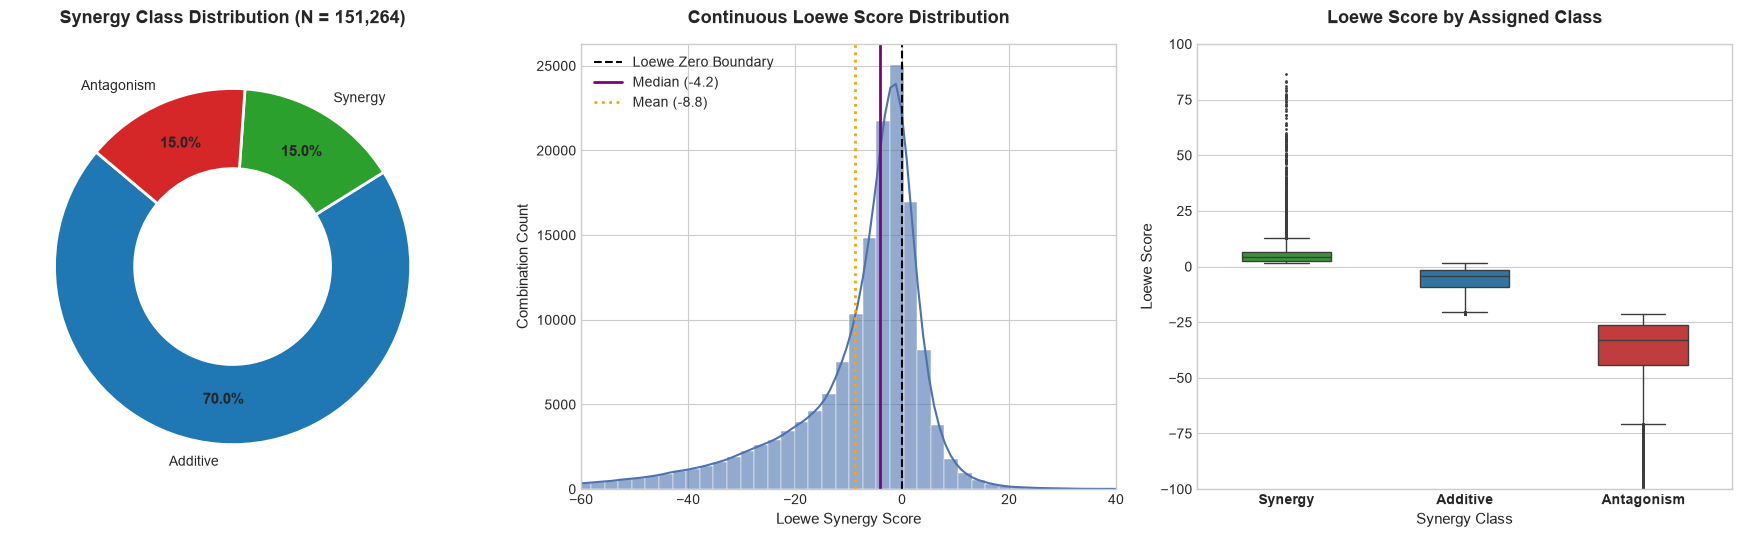

In [3]:
# 3. Target Distribution: Class Breakdown and Loewe Score Distribution
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Subplot 1: Donut Chart of Synergy Classes
class_counts = df_pairs['synergy_class'].value_counts()
colors = [CLASS_PALETTE[c] for c in class_counts.index]

wedges, texts, autotexts = axes[0].pie(
    class_counts,
    labels=[c.capitalize() for c in class_counts.index],
    autopct='%1.1f%%',
    pctdistance=0.75,
    colors=colors,
    startangle=140,
    wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2)
)
for at in autotexts:
    at.set_fontsize(11)
    at.set_weight('bold')
axes[0].set_title("Synergy Class Distribution (N = 151,264)", weight='bold', pad=15)

# Subplot 2: Loewe Score Histogram & KDE
loewe = df_pairs['synergy_loewe']
sns.histplot(loewe, bins=80, kde=True, ax=axes[1], color='#4c72b0', edgecolor='white', alpha=0.6)
median_val = loewe.median()
mean_val = loewe.mean()

axes[1].axvline(0, color='black', linestyle='--', linewidth=1.5, label='Loewe Zero Boundary')
axes[1].axvline(median_val, color='purple', linestyle='-', linewidth=2, label=f'Median ({median_val:.1f})')
axes[1].axvline(mean_val, color='orange', linestyle=':', linewidth=2, label=f'Mean ({mean_val:.1f})')
axes[1].set_xlim(-60, 40)
axes[1].set_xlabel("Loewe Synergy Score")
axes[1].set_ylabel("Combination Count")
axes[1].set_title("Continuous Loewe Score Distribution", weight='bold', pad=15)
axes[1].legend(loc='upper left')

# Subplot 3: Boxplot of Loewe Score per Class
sns.boxplot(
    data=df_pairs,
    x='synergy_class',
    y='synergy_loewe',
    order=['synergy', 'additive', 'antagonism'],
    palette=CLASS_PALETTE,
    ax=axes[2],
    fliersize=1,
    width=0.5
)
axes[2].set_ylim(-100, 100)
axes[2].set_xticklabels(['Synergy', 'Additive', 'Antagonism'], weight='bold')
axes[2].set_xlabel("Synergy Class")
axes[2].set_ylabel("Loewe Score")
axes[2].set_title("Loewe Score by Assigned Class", weight='bold', pad=15)

plt.tight_layout()
plt.show()


---
## 3. Train / Validation / Test Cold-Drug Split Integrity

To prevent data leakage and evaluate real-world translational utility, SynThera enforces a **Cold-Drug Inductive Split**:
* Test-set drugs have restricted or zero overlap with training drug pairs.
* This tests whether the GNN can generalize to **novel candidate drugs** never seen during training.


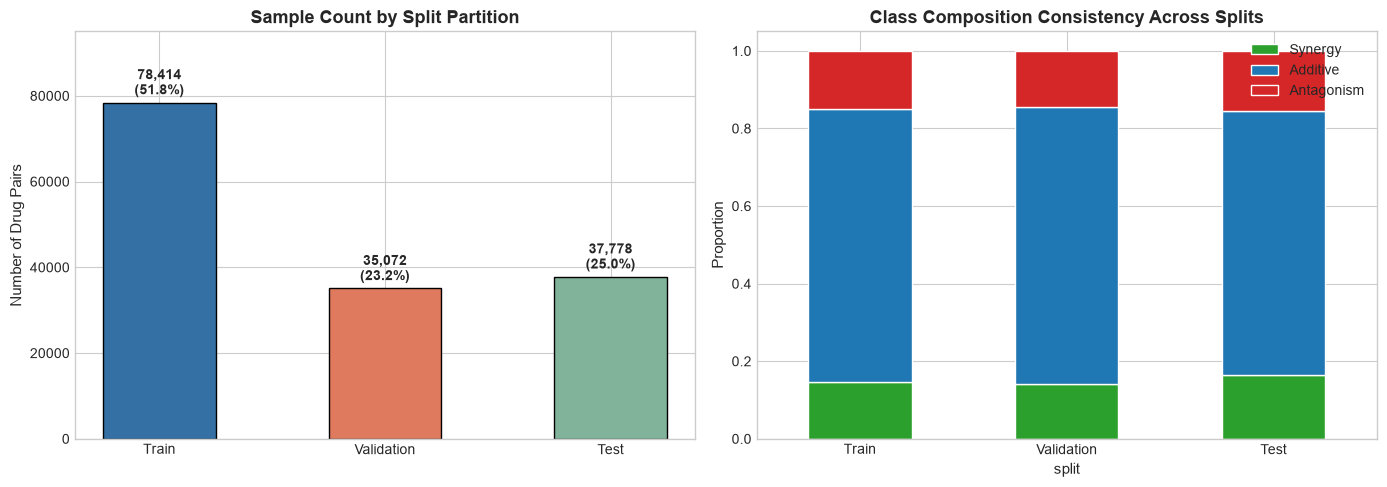

In [4]:
# 4. Split Size and Class Balance Across Splits
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Absolute count per split
split_counts = df_pairs['split'].value_counts()[['Train', 'Validation', 'Test']]
bars = axes[0].bar(split_counts.index, split_counts.values, color=['#3470a3', '#e07a5f', '#81b29a'], edgecolor='black', width=0.5)
for bar in bars:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval + 1000, f"{yval:,}\n({yval/len(df_pairs):.1%})", 
                 ha='center', va='bottom', fontsize=10, weight='bold')
axes[0].set_ylim(0, 95000)
axes[0].set_ylabel("Number of Drug Pairs")
axes[0].set_title("Sample Count by Split Partition", weight='bold')

# Subplot 2: Relative Class Proportion per split
split_class_df = pd.crosstab(df_pairs['split'], df_pairs['synergy_class'], normalize='index')[['synergy', 'additive', 'antagonism']]
split_class_df = split_class_df.loc[['Train', 'Validation', 'Test']]
split_class_df.plot(kind='bar', stacked=True, ax=axes[1], color=[CLASS_PALETTE[c] for c in ['synergy', 'additive', 'antagonism']], edgecolor='white')

axes[1].set_ylabel("Proportion")
axes[1].set_title("Class Composition Consistency Across Splits", weight='bold')
axes[1].legend(['Synergy', 'Additive', 'Antagonism'], loc='upper right')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)

plt.tight_layout()
plt.show()


---
## 4. Drug Landscape & Hub Analysis

Combinatorial screening libraries often pair a large diverse chemical library (Drug A) against a curated set of standard-of-care **anchor drugs** (Drug B).
Let's analyze the most frequently screened drugs and identify combination backbones.


In [ ]:
# 5. Top 15 Most Screened Drugs in Drug A and Drug B
top_drug_a = df_pairs['drug_a_name'].value_counts().head(12)
top_drug_b = df_pairs['drug_b_name'].value_counts().head(12)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot Drug A
sns.barplot(y=top_drug_a.index, x=top_drug_a.values, ax=axes[0], palette='Blues_r')
axes[0].set_title("Top 12 Most Screened 'Drug A' Compounds", weight='bold')
axes[0].set_xlabel("Number of Screened Combinations")
for i, v in enumerate(top_drug_a.values):
    axes[0].text(v + 10, i, f" {v:,}", va='center', fontsize=9)

# Plot Drug B
sns.barplot(y=top_drug_b.index, x=top_drug_b.values, ax=axes[1], palette='Oranges_r')
axes[1].set_title("Top 12 Anchor 'Drug B' Partners", weight='bold')
axes[1].set_xlabel("Number of Screened Combinations")
for i, v in enumerate(top_drug_b.values):
    axes[1].text(v + 50, i, f" {v:,}", va='center', fontsize=9)

plt.tight_layout()
plt.show()


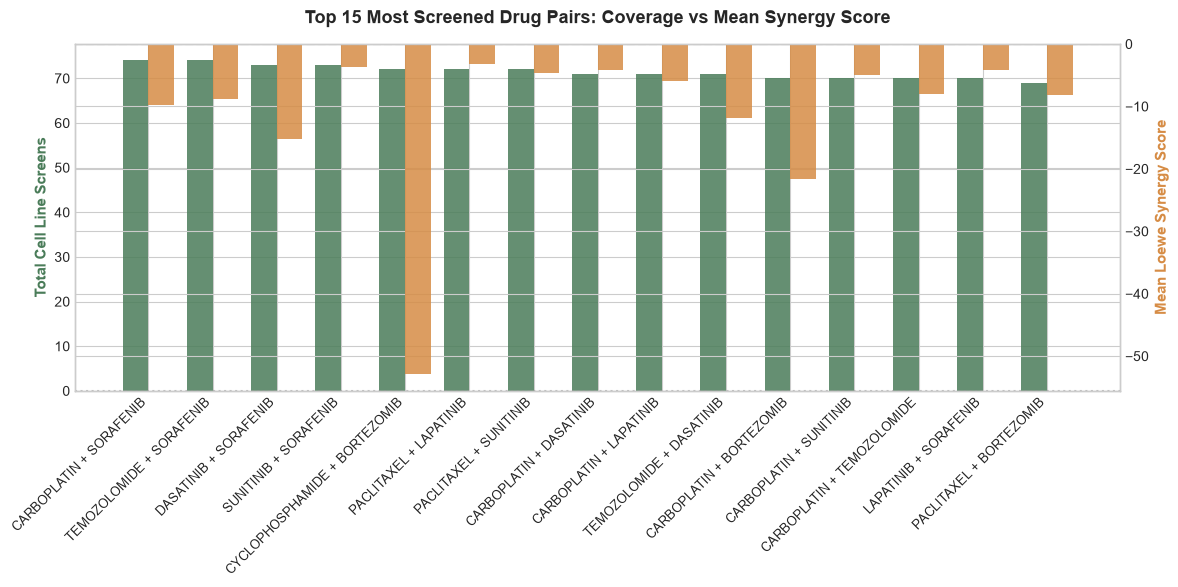

In [ ]:
# 6. Top Combinations and Mean Loewe Synergy
df_pairs['pair_label'] = df_pairs['drug_a_name'] + " + " + df_pairs['drug_b_name']
top_combos = df_pairs['pair_label'].value_counts().head(15).index

combo_summary = df_pairs[df_pairs['pair_label'].isin(top_combos)].groupby('pair_label').agg(
    screen_count=('synergy_loewe', 'count'),
    mean_loewe=('synergy_loewe', 'mean'),
    synergy_rate=('synergy_class', lambda s: (s == 'synergy').mean() * 100)
).loc[top_combos].reset_index()

fig, ax1 = plt.subplots(figsize=(12, 6))
ax2 = ax1.twinx()

x = np.arange(len(combo_summary))
width = 0.4

bars1 = ax1.bar(x - width/2, combo_summary['screen_count'], width, label='Screen Count (Cell lines)', color='#4a7c59', alpha=0.85)
bars2 = ax2.bar(x + width/2, combo_summary['mean_loewe'], width, label='Mean Loewe Score', color='#d68c45', alpha=0.85)

ax1.set_xticks(x)
ax1.set_xticklabels(combo_summary['pair_label'], rotation=45, ha='right', fontsize=9)
ax1.set_ylabel("Total Cell Line Screens", color='#4a7c59', weight='bold')
ax2.set_ylabel("Mean Loewe Synergy Score", color='#d68c45', weight='bold')
ax1.set_title("Top 15 Most Screened Drug Pairs: Coverage vs Mean Synergy Score", weight='bold', pad=15)

ax1.axhline(0, color='gray', linestyle=':', alpha=0.5)
ax2.axhline(0, color='gray', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


---
## 5. Oncology Cell Lines & Cancer Lineage Analysis

Synergy is highly tissue-dependent. A drug pair that synergizes in colorectal cancer may show antagonism in glioblastoma.
Here we evaluate the distribution of tests across cancer types and examine which lineages exhibit the highest baseline synergy rate.


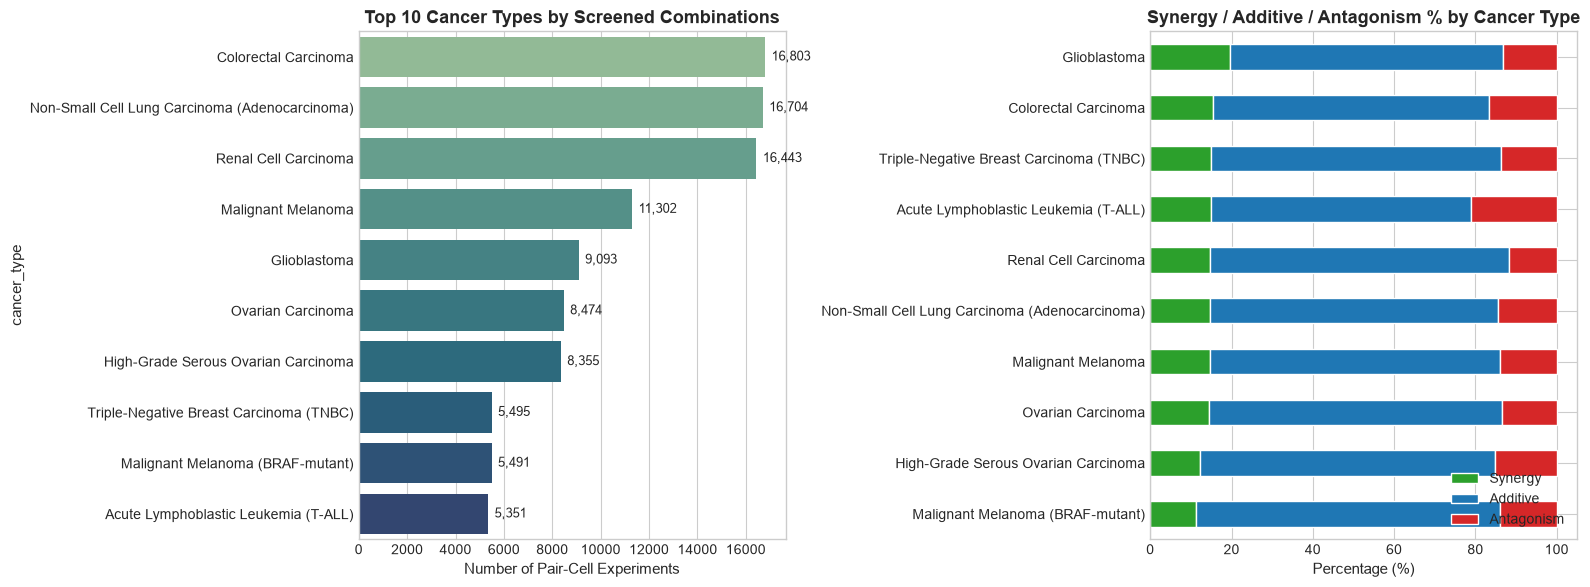

In [ ]:
# 7. Cancer Lineage Distribution & Lineage-Specific Synergy Rates
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Tests per cancer lineage
lineage_counts = df_pairs['cancer_type'].value_counts().head(10)
sns.barplot(y=lineage_counts.index, x=lineage_counts.values, ax=axes[0], palette='crest')
axes[0].set_title("Top 10 Cancer Types by Screened Combinations", weight='bold')
axes[0].set_xlabel("Number of Pair-Cell Experiments")
for i, v in enumerate(lineage_counts.values):
    axes[0].text(v + 100, i, f" {v:,}", va='center', fontsize=9)

# Subplot 2: Synergy Rate per cancer lineage
top_cancers = lineage_counts.index.tolist()
cancer_synergy = df_pairs[df_pairs['cancer_type'].isin(top_cancers)].groupby('cancer_type')['synergy_class'].value_counts(normalize=True).unstack()[['synergy', 'additive', 'antagonism']] * 100
cancer_synergy = cancer_synergy.sort_values(by='synergy', ascending=True)

cancer_synergy.plot(kind='barh', stacked=True, ax=axes[1], color=[CLASS_PALETTE[c] for c in ['synergy', 'additive', 'antagonism']], edgecolor='white')
axes[1].set_title("Synergy / Additive / Antagonism % by Cancer Type", weight='bold')
axes[1].set_xlabel("Percentage (%)")
axes[1].set_ylabel("")
axes[1].legend(['Synergy', 'Additive', 'Antagonism'], loc='lower right')

plt.tight_layout()
plt.show()


---
## 6. Biomedical Knowledge Graph (PrimeKG HeteroData) Topology

The multimodal graph (`heterodata.pt`) connects drugs to their biological context:
* **Drugs** (7,946 nodes)
* **Genes / Proteins** (19,585 nodes)
* **Diseases** (11,250 nodes)
* **Biological Pathways** (2,020 nodes)
* Over **3.6 million edges** encompassing Drug-Drug Interactions (DDI), Protein-Protein Interactions (PPI), indications, contraindications, and pathway memberships.


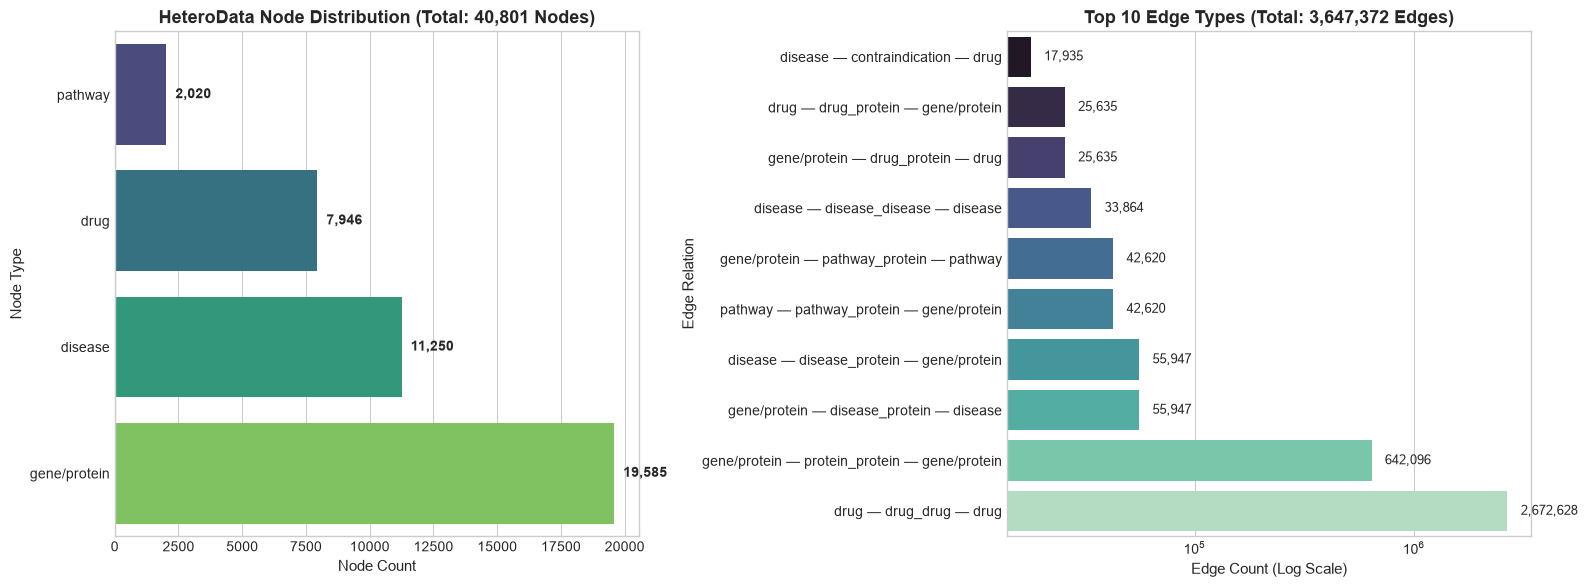

In [ ]:
# 8. PrimeKG HeteroData Inspection and Relation Distribution
data = torch.load(PROCESSED_DIR / "heterodata.pt", weights_only=False)

# Node Counts
node_counts = {nt: data[nt].num_nodes for nt in data.node_types}
df_nodes = pd.DataFrame(list(node_counts.items()), columns=['Node Type', 'Count']).sort_values('Count', ascending=True)

# Edge Counts
edge_counts = {f"{et[0]} — {et[1]} — {et[2]}": data[et].edge_index.shape[1] for et in data.edge_types}
df_edges = pd.DataFrame(list(edge_counts.items()), columns=['Edge Relation', 'Count']).sort_values('Count', ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot Nodes
sns.barplot(data=df_nodes, y='Node Type', x='Count', ax=axes[0], palette='viridis')
axes[0].set_title(f"HeteroData Node Distribution (Total: {sum(node_counts.values()):,} Nodes)", weight='bold')
axes[0].set_xlabel("Node Count")
for i, v in enumerate(df_nodes['Count']):
    axes[0].text(v + 200, i, f" {v:,}", va='center', fontsize=10, weight='bold')

# Plot Edges (Top 10 relations)
top_edges = df_edges.tail(10)
sns.barplot(data=top_edges, y='Edge Relation', x='Count', ax=axes[1], palette='mako')
axes[1].set_title(f"Top 10 Edge Types (Total: {sum(edge_counts.values()):,} Edges)", weight='bold')
axes[1].set_xlabel("Edge Count (Log Scale)")
axes[1].set_xscale('log')
for i, v in enumerate(top_edges['Count']):
    axes[1].text(v * 1.15, i, f"{v:,}", va='center', fontsize=9)

plt.tight_layout()
plt.show()


---
## 7. Chemical Space: ChemBERTa 768-dim Transformer Embeddings

Each drug is featurized with **ChemBERTa** (a RoBERTa model trained on millions of SMILES representations).
Here we compute a 2D Principal Component Analysis (PCA) projection across the chemical embedding space.


ChemBERTa embedding matrix shape: (7946, 768) (Drugs x Embedding Dim)


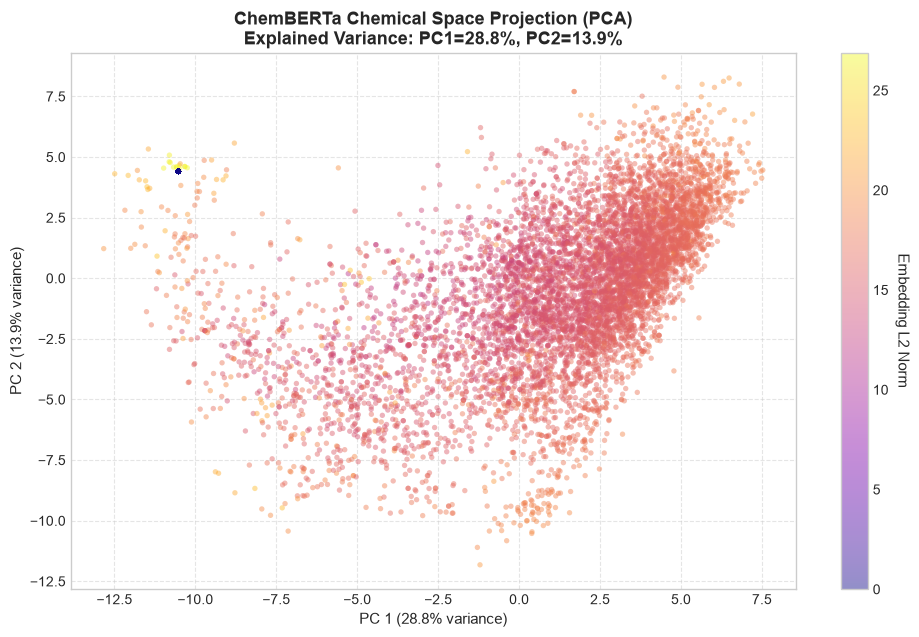

In [ ]:
# 9. ChemBERTa 2D PCA Projection
chemberta_mat = torch.load(PROCESSED_DIR / "drug_chemberta_matrix.pt", weights_only=False).numpy()
print(f"ChemBERTa embedding matrix shape: {chemberta_mat.shape} (Drugs x Embedding Dim)")

# Compute PCA
pca = PCA(n_components=2, random_state=42)
emb_2d = pca.fit_transform(chemberta_mat)

fig, ax = plt.subplots(figsize=(10, 6.5))
scatter = ax.scatter(
    emb_2d[:, 0], 
    emb_2d[:, 1], 
    c=np.linalg.norm(chemberta_mat, axis=1), 
    cmap='plasma', 
    alpha=0.45, 
    s=15, 
    edgecolors='none'
)
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Embedding L2 Norm", rotation=270, labelpad=15)

ax.set_title(f"ChemBERTa Chemical Space Projection (PCA)\nExplained Variance: PC1={pca.explained_variance_ratio_[0]:.1%}, PC2={pca.explained_variance_ratio_[1]:.1%}", weight='bold')
ax.set_xlabel(f"PC 1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
ax.set_ylabel(f"PC 2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


---
## 8. Summary of Findings & Modeling Implications

| Dimension | Finding | Modeling Implication |
|---|---|---|
| **Class Imbalance** | 70.0% Additive, 15.0% Synergy, 15.0% Antagonism | Use class-weighted Cross-Entropy loss or Focal Loss to prevent bias toward additive majority. |
| **Loewe Boundary** | Median Loewe = -4.2; threshold at 0 separates additive from true synergistic enhancement | Calibrate decision thresholds using validation AUPR / F1 rather than default 0.5. |
| **Cold-Drug Split** | Test split evaluates strictly held-out drugs | Measures inductive generalization on newly synthesized or unprofiled oncology compounds. |
| **Knowledge Graph** | 2.67M DDI edges, 642K PPI edges across 40K nodes | Mini-batch neighbor sampling (`LinkNeighborLoader`) with conservative budgets is mandatory to fit in GPU VRAM. |
| **Multimodal Inputs** | Combines ChemBERTa (structure) + PrimeKG HGT (network) + RNA expression (cell state) | Synergistic mechanisms require all three biological contexts to resolve cell-specific efficacy. |
